In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import scienceplots

plt.style.use("science")

import os
from ase.formula import Formula

In [2]:
synth_df = pd.read_csv("../data/synthesized_MAXphases.csv")
synth_df.columns = ["MAX"]
pu_labels = pd.read_csv("../data/pu_labels.csv", index_col=0)

In [3]:
def max2mx(max_name):
    max_counts = Formula(max_name).count()
    del max_counts[list(max_counts)[1]]  # A element is always in position 1
    mx_name_unsorted = "".join([f"{atom}{count}" for atom, count in max_counts.items()])
    return Formula(mx_name_unsorted).format("metal")

In [4]:
known_mxenes = [max2mx(max_phase) for max_phase in pu_labels[pu_labels["class"]!=0].index]
known_mxenes = list(set(known_mxenes))

# Visualisation of the pseudo-positivity scores and generation of the tables

In [5]:
def plot_score_histogram(df, save_to=None, use_subset=False):
    global synth_df

    if use_subset:
        df = df[["Probability of pseudo-positivity", "Original cluster", "MXene"]]
    df.columns = ["Convertibility", "Cluster", "MXene"]

    known_max = df[df.index.isin(synth_df.MAX)]
    unknown_max = df[~df.index.isin(synth_df.MAX)]

    plt.hist(known_max["Convertibility"], bins=np.linspace(0,1,25), log=True, edgecolor="navy", color="white", alpha=1, rwidth=0.5, zorder=2)
    plt.hist(unknown_max["Convertibility"], bins=np.linspace(0,1,25), log=True, edgecolor="darkred", color="red", linewidth=1.2, alpha=1, zorder=1)
    plt.legend(labels=["Synthesized MAX phase", "Not yet synthesized MAX phase"])
    plt.xlabel("Convertibility score")
    plt.ylabel("Number of MAX phases")
    plt.tight_layout()
    if save_to is not None:
        plt.savefig(save_to, bbox_inches="tight")

In [6]:
def generate_tables(df, threshold=0.8, print_latex=False, use_subset=False):
    global synth_df, pu_labels, known_mxenes

    if use_subset:
        df = df[["Probability of pseudo-positivity", "Original cluster", "MXene"]]
    df.columns = ["Convertibility", "Cluster", "MXene"]

    df = df[df["Convertibility"]>=threshold]
    df = df.reset_index(names="MAX")

    df["SynthesizedMAX"] = df.MAX.isin(synth_df.MAX)
    df["SynthesizedMX"] = df.MXene.isin(known_mxenes)
    
    indicator = df.MAX.isin(pu_labels[pu_labels["class"]!=0].index)
    df["MAX"] = r"\ce{"+df["MAX"]+"}"
    df["MXene"] = r" \ce{"+df["MXene"]+"}"
    df.loc[indicator, "MAX"] = r"\textbf{"+df.loc[indicator, "MAX"]+"}"

    df["Value"] = df["MAX"] + " ("+df["Convertibility"].round(decimals=3).astype(str)+")"

    for indicator in [df.SynthesizedMX, ~df.SynthesizedMX]:
        result_df = df[indicator].sort_values(["MXene","Convertibility"], ascending=[True,False]).copy()
        result_df.drop(["Convertibility","Cluster","SynthesizedMX", "MAX"], axis=1, inplace=True)
        g=result_df.groupby(["MXene","SynthesizedMAX"]).cumcount().add(1)
        result_df = result_df.set_index(["MXene","SynthesizedMAX",g])["Value"].unstack(level=1).droplevel(level=1).rename_axis(None,axis=1).reset_index()
        result_df = result_df.fillna("")
        result_df.columns = ["MXene", "Non-synthesized MAX phases", "Synthesized MAX phases"]
        result_df = result_df[[result_df.columns[i] for i in [0,2,1]]] # Permute columns
        display(result_df)
        if print_latex:
            print(result_df.to_latex(index_names=False, index=False))
            

16.0
0.567852738980773


,MXene,Synthesized MAX phases,Non-synthesized MAX phases
0,\ce{Nb2C},\textbf{\ce{Nb2AlC}} (0.947),
1,\ce{Nb2C},\ce{Nb2GaC} (0.944),
2,\ce{Nb2C},\ce{Nb2InC} (0.878),
3,\ce{Nb2C},\ce{Nb2CuC} (0.835),
4,\ce{Nb4C3},\textbf{\ce{Nb4AlC3}} (0.832),\ce{Nb4GaC3} (0.837)
5,\ce{Nb4C3},,\ce{Nb4InC3} (0.805)
6,\ce{Ta2C},\textbf{\ce{Ta2AlC}} (0.94),\ce{Ta2InC} (0.863)
7,\ce{Ta2C},\ce{Ta2GaC} (0.935),
8,\ce{Ta4C3},\textbf{\ce{Ta4AlC3}} (0.884),\ce{Ta4GaC3} (0.892)
9,\ce{Ta4C3},,\ce{Ta4InC3} (0.871)


\begin{tabular}{lll}
\toprule
MXene & Synthesized MAX phases & Non-synthesized MAX phases \\
\midrule
 \ce{Nb2C} & \textbf{\ce{Nb2AlC}} (0.947) &  \\
 \ce{Nb2C} & \ce{Nb2GaC} (0.944) &  \\
 \ce{Nb2C} & \ce{Nb2InC} (0.878) &  \\
 \ce{Nb2C} & \ce{Nb2CuC} (0.835) &  \\
 \ce{Nb4C3} & \textbf{\ce{Nb4AlC3}} (0.832) & \ce{Nb4GaC3} (0.837) \\
 \ce{Nb4C3} &  & \ce{Nb4InC3} (0.805) \\
 \ce{Ta2C} & \textbf{\ce{Ta2AlC}} (0.94) & \ce{Ta2InC} (0.863) \\
 \ce{Ta2C} & \ce{Ta2GaC} (0.935) &  \\
 \ce{Ta4C3} & \textbf{\ce{Ta4AlC3}} (0.884) & \ce{Ta4GaC3} (0.892) \\
 \ce{Ta4C3} &  & \ce{Ta4InC3} (0.871) \\
 \ce{Ti2C} & \textbf{\ce{Ti2AlC}} (0.992) & \ce{Ti2CoC} (0.995) \\
 \ce{Ti2C} & \textbf{\ce{Ti2GaC}} (0.979) & \ce{Ti2RuC} (0.99) \\
 \ce{Ti2C} & \ce{Ti2InC} (0.866) & \ce{Ti2RhC} (0.989) \\
 \ce{Ti2C} &  & \ce{Ti2NiC} (0.989) \\
 \ce{Ti2C} &  & \ce{Ti2MnC} (0.988) \\
 \ce{Ti2C} &  & \ce{Ti2FeC} (0.987) \\
 \ce{Ti2C} &  & \ce{Ti2CuC} (0.946) \\
 \ce{Ti2C} &  & \ce{Ti2TeC} (0.891) \\
 \ce{Ti2C} &  & \ce{

,MXene,Synthesized MAX phases,Non-synthesized MAX phases
0,\ce{Nb3C2},,\ce{Nb3GaC2} (0.927)
1,\ce{Nb3C2},,\ce{Nb3AlC2} (0.926)
2,\ce{Nb3C2},,\ce{Nb3InC2} (0.888)
3,\ce{Sc2N},,\ce{Sc2AlN} (0.833)
4,\ce{Sc3N2},,\ce{Sc3AlN2} (0.873)
5,\ce{Sc4N3},,\ce{Sc4AlN3} (0.828)
6,\ce{Ta3C2},\ce{Ta3AlC2} (0.935),\ce{Ta3GaC2} (0.938)
7,\ce{Ta3C2},,\ce{Ta3InC2} (0.905)
8,\ce{Ti3N2},,\ce{Ti3AlN2} (0.947)
9,\ce{Ti3N2},,\ce{Ti3GaN2} (0.808)


\begin{tabular}{lll}
\toprule
MXene & Synthesized MAX phases & Non-synthesized MAX phases \\
\midrule
 \ce{Nb3C2} &  & \ce{Nb3GaC2} (0.927) \\
 \ce{Nb3C2} &  & \ce{Nb3AlC2} (0.926) \\
 \ce{Nb3C2} &  & \ce{Nb3InC2} (0.888) \\
 \ce{Sc2N} &  & \ce{Sc2AlN} (0.833) \\
 \ce{Sc3N2} &  & \ce{Sc3AlN2} (0.873) \\
 \ce{Sc4N3} &  & \ce{Sc4AlN3} (0.828) \\
 \ce{Ta3C2} & \ce{Ta3AlC2} (0.935) & \ce{Ta3GaC2} (0.938) \\
 \ce{Ta3C2} &  & \ce{Ta3InC2} (0.905) \\
 \ce{Ti3N2} &  & \ce{Ti3AlN2} (0.947) \\
 \ce{Ti3N2} &  & \ce{Ti3GaN2} (0.808) \\
 \ce{Ti4C3} & \ce{Ti4GaC3} (0.866) & \ce{Ti4AlC3} (0.942) \\
 \ce{V2N} &  & \ce{V2AlN} (0.816) \\
 \ce{V3C2} &  & \ce{V3AlC2} (0.99) \\
 \ce{V3C2} &  & \ce{V3GaC2} (0.986) \\
 \ce{V3C2} &  & \ce{V3CuC2} (0.984) \\
 \ce{V3C2} &  & \ce{V3InC2} (0.966) \\
 \ce{V3C2} &  & \ce{V3AgC2} (0.96) \\
 \ce{Y2N} &  & \ce{Y2AlN} (0.806) \\
 \ce{Y3N2} &  & \ce{Y3AlN2} (0.854) \\
 \ce{Y4N3} &  & \ce{Y4AlN3} (0.806) \\
 \ce{Zr2C} & \ce{Zr2AlC} (0.9) &  \\
 \ce{Zr2N} &  & \ce{Zr2AlN}

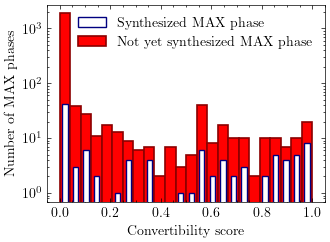

In [7]:
df = pd.read_excel(os.path.join("..","results","scoring","svc_5", "pumkl", "svc_pumkl_150_scores.xlsx"), sheet_name=0, index_col=0)
print(df.loc[pu_labels[pu_labels["class"]!=0].index, "Total Score"].round().sum())
print(df.loc[pu_labels[pu_labels["class"]!=0].index, "Total Score"].min())
plot_score_histogram(df, "histogram_pseudo_positivity_svc.pdf")
generate_tables(df, print_latex=True)